<a href="https://colab.research.google.com/github/HannaSkrypnyk/DTA-Python-26/blob/main/Hanna_07_%D0%A4%D1%96%D0%BD%D0%B0%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D0%BF%D1%80%D0%BE%D1%94%D0%BA%D1%82_02_11_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐼📈 Pandas і графіки для аналітиків · Блокнот 7 з 7
## Фінальний проєкт · 📈 Дашборд для керівника

### 🎯 Ваше завдання
Ви — аналітик інтернет-магазину. Керівник пише:

> «Привіт! Підготуй, будь ласка, підсумки 2025 року: скільки заробили, як ішли продажі по місяцях, які товари й міста найкращі, хто наші клієнти і де проблеми. Зроби одну картинку-дашборд і скинь усе в Excel, щоб я міг показати на нараді.»

У вас три файли: **`orders.csv`**, **`customers.csv`**, **`products.csv`**. Як і в більшості реальних компаній, дані в них **англійською**.

### Як працювати
- Проєкт складається з **11 кроків**. У тілі блокнота — **лише завдання**, щоб ви могли спробувати все зробити самостійно.
- 💡 **Підказки** до кожного кроку зібрано **в кінці блокнота**, у розділі «Підказки».
- ✅ Ще нижче — **розв'язки** (сховані, натисніть «Показати код»).
- ⚠️ Використовуйте **назви змінних із завдань** (`data`, `delivered`, `monthly` …): наступні кроки на них спираються. Якщо застрягли на якомусь кроці, запустіть його розв'язок у кінці блокнота: він створить потрібні змінні, і можна повертатися до наступного кроку.


## 📖 Опис даних

**`orders.csv`** — замовлення (3000 рядків)

| Стовпець | Що означає | Значення |
|---|---|---|
| `order_id` | номер замовлення | 100001 … 103000 |
| `order_date` | дата замовлення | 2025-01-01 … 2025-12-31 |
| `delivery_date` | дата доставки | порожньо, якщо замовлення скасували |
| `customer_id` | код клієнта | C0001 … C0400 |
| `product_id` | код товару | P01 … P18 |
| `quantity` | кількість одиниць | 1–4 |
| `payment` | спосіб оплати | `Card` — картка, `Cash on delivery` — накладений платіж, `Google/Apple Pay` |
| `channel` | канал продажів | `Website` — сайт, `App` — мобільний додаток, `Instagram` |
| `status` | статус замовлення | `Delivered` — доставлено, `Cancelled` — скасовано, `Returned` — повернено |
| `rating` | оцінка клієнта, 1–5 | порожньо, якщо клієнт не оцінив |

**`customers.csv`** — клієнти (400 рядків)

| Стовпець | Що означає | Значення |
|---|---|---|
| `customer_id` | код клієнта | C0001 … C0400 |
| `name` | ім'я | Olena, Andrii, … |
| `city` | місто | `Kyiv`, `Lviv`, `Odesa`, `Kharkiv`, `Dnipro` |
| `age` | вік | 18–65 |
| `registration_date` | дата реєстрації | 2022–2024 |

**`products.csv`** — товари (18 рядків)

| Стовпець | Що означає | Значення |
|---|---|---|
| `product_id` | код товару | P01 … P18 |
| `product` | назва | Headphones, Smartwatch, T-shirt, Mug, … |
| `category` | категорія | `Electronics` — електроніка, `Clothing` — одяг, `Home` — дім, `Beauty` — краса, `Sports` — спорт |
| `price` | ціна за одиницю, грн | 180–4200 |
| `cost` | собівартість одиниці, грн | 60–2900 |

⚠️ Текстові значення в умовах треба писати **точно так, як у даних**, з тим самим регістром: `"Delivered"`, а не `"delivered"`.

## Крок 0. Дані та бібліотеки

In [1]:
# @title 📦 Підготовка даних — просто запустіть цю клітинку (Shift + Enter)
# Ця клітинка створює три файли з даними інтернет-магазину за 2025 рік (дані англійською).
# Розбиратися в її коді не потрібно.
# Якщо Colab перезапустився і файли зникли — просто запустіть її ще раз.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2025)

# ---------- Товари ----------
products = pd.DataFrame([
    ("P01", "Headphones",        "Electronics", 1500,  900),
    ("P02", "Power bank",        "Electronics",  900,  520),
    ("P03", "Smartwatch",        "Electronics", 4200, 2900),
    ("P04", "Bluetooth speaker", "Electronics", 2100, 1300),
    ("P05", "T-shirt",           "Clothing",       450,  180),
    ("P06", "Hoodie",            "Clothing",      1200,  550),
    ("P07", "Jeans",             "Clothing",      1600,  800),
    ("P08", "Sneakers",          "Clothing",      2800, 1600),
    ("P09", "Mug",               "Home",          180,   60),
    ("P10", "Blanket",           "Home",          850,  400),
    ("P11", "Desk lamp",         "Home",         1100,  600),
    ("P12", "Towel set",         "Home",          650,  300),
    ("P13", "Face cream",        "Beauty",       520,  210),
    ("P14", "Shampoo",           "Beauty",       260,  110),
    ("P15", "Perfume",           "Beauty",      2400, 1300),
    ("P16", "Yoga mat",          "Sports",       700,  320),
    ("P17", "Water bottle",      "Sports",       350,  140),
    ("P18", "Dumbbells 5 kg",    "Sports",       950,  550),
], columns=["product_id", "product", "category", "price", "cost"])

# ---------- Клієнти ----------
n_cust = 400
names = ["Olena", "Andrii", "Mariia", "Ihor", "Nataliia", "Dmytro", "Iryna", "Oleksandr",
         "Tetiana", "Serhii", "Yuliia", "Maksym", "Oksana", "Viktor", "Anna", "Bohdan",
         "Kateryna", "Taras", "Sofiia", "Roman"]
cities = ["Kyiv", "Lviv", "Odesa", "Kharkiv", "Dnipro"]
reg = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 3 * 365, n_cust), unit="D")
customers = pd.DataFrame({
    "customer_id": [f"C{i:04d}" for i in range(1, n_cust + 1)],
    "name": rng.choice(names, n_cust),
    "city": rng.choice(cities, n_cust, p=[0.35, 0.2, 0.15, 0.15, 0.15]),
    "age": np.clip(rng.normal(33, 9, n_cust).round(), 18, 65).astype(int),
    "registration_date": reg.strftime("%Y-%m-%d"),
})

# ---------- Замовлення ----------
n = 3000
days = pd.date_range("2025-01-01", "2025-12-31")
w = np.linspace(0.85, 1.15, len(days))          # магазин поступово росте
w[days.month.isin([6, 7, 8])] *= 0.8            # влітку спокійніше
w[days.month.isin([11, 12])] *= 1.5             # сезон розпродажів і свят
w[days.dayofweek >= 5] *= 1.3                   # у вихідні купують більше
w[days == pd.Timestamp("2025-11-28")] *= 6      # Чорна п'ятниця
order_date = pd.DatetimeIndex(np.sort(rng.choice(days.values, n, p=w / w.sum())))

cust_w = rng.gamma(1.0, 1, n_cust)
cust_idx = rng.choice(n_cust, n, p=cust_w / cust_w.sum())
prod_w = 1 / np.sqrt(products["price"].to_numpy())
prod_idx = rng.choice(len(products), n, p=prod_w / prod_w.sum())

quantity = rng.choice([1, 2, 3, 4], n, p=[0.72, 0.18, 0.07, 0.03])
payment = rng.choice(["Card", "Cash on delivery", "Google/Apple Pay"], n, p=[0.55, 0.27, 0.18])
channel = rng.choice(["Website", "App", "Instagram"], n, p=[0.5, 0.35, 0.15])

cod = payment == "Cash on delivery"
u = rng.random(n)
status = np.where(u < np.where(cod, 0.80, 0.91), "Delivered",
                  np.where(u < np.where(cod, 0.92, 0.96), "Cancelled", "Returned"))

city = customers["city"].to_numpy()[cust_idx]
deliv_days = np.where(city == "Kyiv", rng.integers(1, 3, n), rng.integers(1, 6, n))
delivery = order_date + pd.to_timedelta(deliv_days, unit="D")
delivery_str = np.where(status == "Cancelled", None, delivery.strftime("%Y-%m-%d"))

rating = np.where(deliv_days >= 4,
                  rng.choice(5, n, p=[0.08, 0.12, 0.22, 0.33, 0.25]) + 1,
                  rng.choice(5, n, p=[0.03, 0.05, 0.12, 0.35, 0.45]) + 1).astype(float)
returned = status == "Returned"
rating[returned] = rng.choice([1, 2, 3], returned.sum(), p=[0.5, 0.3, 0.2])
rating[(status == "Cancelled") | (rng.random(n) > 0.6)] = np.nan

orders = pd.DataFrame({
    "order_id": np.arange(100001, 100001 + n),
    "order_date": order_date.strftime("%Y-%m-%d"),
    "delivery_date": delivery_str,
    "customer_id": customers["customer_id"].to_numpy()[cust_idx],
    "product_id": products["product_id"].to_numpy()[prod_idx],
    "quantity": quantity,
    "payment": payment,
    "channel": channel,
    "status": status,
    "rating": rating,
})

# ---------- Зберігаємо файли ----------
orders.to_csv("orders.csv", index=False)
customers.to_csv("customers.csv", index=False)
products.to_csv("products.csv", index=False)

# ---------- Налаштування вигляду таблиць і стиль графіків ----------
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})

del (rng, names, cities, reg, n, n_cust, days, w, order_date, cust_w, cust_idx, prod_w, prod_idx,
     quantity, payment, channel, cod, u, status, city, deliv_days, delivery, delivery_str, rating,
     returned, orders, customers, products)

print("✅ Готово! Створено файли: orders.csv, customers.csv, products.csv")

✅ Готово! Створено файли: orders.csv, customers.csv, products.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Крок 1. Завантаження і перевірка даних

**Завдання:**
1. Прочитайте три файли у змінні `orders`, `customers`, `products`.
2. Для кожної таблиці подивіться розмір, перші рядки та пропуски.
3. Перевірте, що ключі унікальні: `order_id` у замовленнях, `customer_id` у клієнтах, `product_id` у товарах.
4. Поясніть собі: чому в деяких стовпцях є пропуски? Це помилка в даних чи ні?

In [11]:
# Ваш код тут

orders = pd.read_csv("orders.csv")
customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")

# 2. Розмір, перші рядки, типи та пропуски
for name, df in [("orders", orders), ("customers", customers), ("products", products)]:
  print(f"{name}: {df.shape[0]} рядків, {df.shape[1]} стовпців")
  display(df.head())
  df.info()
  print("\nПропуски:")
  print(df.isna().sum()[df.isna().sum() > 0])     # тільки стовпці з пропусками

# 3. Перевірка унікальності ключів
print("\nДублікати ключів:")
print("order_id:"   , orders["order_id"].duplicated().sum())
print("customer_id:", customers["customer_id"].duplicated().sum())
print("product_id:" , products["product_id"].duplicated().sum())


orders: 3000 рядків, 10 стовпців


,order_id,order_date,delivery_date,customer_id,product_id,quantity,payment,channel,status,rating
0,100001,2025-01-01,NaN,C0230,P18,4,Card,Website,Cancelled,NaN
1,100002,2025-01-01,2025-01-02,C0074,P03,3,Google/Apple Pay,Website,Delivered,5.00
2,100003,2025-01-01,2025-01-05,C0216,P03,1,Google/Apple Pay,Website,Delivered,NaN
3,100004,2025-01-01,2025-01-02,C0219,P04,1,Cash on delivery,Instagram,Delivered,5.00
4,100005,2025-01-01,2025-01-06,C0026,P11,1,Card,App,Delivered,4.00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       3000 non-null   int64  
 1   order_date     3000 non-null   object 
 2   delivery_date  2795 non-null   object 
 3   customer_id    3000 non-null   object 
 4   product_id     3000 non-null   object 
 5   quantity       3000 non-null   int64  
 6   payment        3000 non-null   object 
 7   channel        3000 non-null   object 
 8   status         3000 non-null   object 
 9   rating         1745 non-null   float64
dtypes: float64(1), int64(2), object(7)
memory usage: 234.5+ KB

Пропуски:
delivery_date     205
rating           1255
dtype: int64
customers: 400 рядків, 5 стовпців


,customer_id,name,city,age,registration_date
0,C0001,Sofiia,Lviv,29,2023-05-05
1,C0002,Tetiana,Dnipro,27,2024-12-24
2,C0003,Andrii,Kharkiv,35,2024-12-22
3,C0004,Iryna,Dnipro,29,2023-02-23
4,C0005,Sofiia,Odesa,40,2024-11-10


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        400 non-null    object
 1   name               400 non-null    object
 2   city               400 non-null    object
 3   age                400 non-null    int64 
 4   registration_date  400 non-null    object
dtypes: int64(1), object(4)
memory usage: 15.8+ KB

Пропуски:
Series([], dtype: int64)
products: 18 рядків, 5 стовпців


,product_id,product,category,price,cost
0,P01,Headphones,Electronics,1500,900
1,P02,Power bank,Electronics,900,520
2,P03,Smartwatch,Electronics,4200,2900
3,P04,Bluetooth speaker,Electronics,2100,1300
4,P05,T-shirt,Clothing,450,180


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   product_id  18 non-null     object
 1   product     18 non-null     object
 2   category    18 non-null     object
 3   price       18 non-null     int64 
 4   cost        18 non-null     int64 
dtypes: int64(2), object(3)
memory usage: 852.0+ bytes

Пропуски:
Series([], dtype: int64)

Дублікати ключів:
order_id: 0
customer_id: 0
product_id: 0


---
## Крок 2. Підготовка: одна велика таблиця

**Завдання:**
1. Перетворіть `order_date` і `delivery_date` у `orders` на дати.
2. Об'єднайте `orders` з `products` і `customers` у таблицю **`data`**. Переконайтеся, що рядків стільки ж, скільки замовлень.
3. Додайте в `data` стовпці:
   - `revenue` — ціна × кількість;
   - `profit` — (ціна − собівартість) × кількість;
   - `month` — місяць замовлення;
   - `delivery_days` — скільки днів ішла доставка.
4. Створіть таблицю **`delivered`**: лише замовлення зі статусом `Delivered`. Саме вони принесли магазину гроші.

In [13]:
orders["delivery_date"] = pd.to_datetime(orders["delivery_date"])
orders["order_date"] = pd.to_datetime(orders["order_date"])

data = (
    orders
    .merge(products, on="product_id", how="left", validate="many_to_one")
    .merge(customers, on="customer_id", how="left", validate="many_to_one")
)
print(f"Замовлень: {len(orders)}, рядків після об'єднання: {len(data)}")

data["revenue"] = data["price"] * data["quantity"]
data["profit"] = (data["price"] - data["cost"]) * data["quantity"]
data["month"] = data["order_date"].dt.to_period("M")
data["delivery_days"] = (data["delivery_date"] - data["order_date"]).dt.days

delivered = data[data["status"] == "Delivered"].copy()

data.head(5)


Замовлень: 3000, рядків після об'єднання: 3000


,order_id,order_date,delivery_date,customer_id,product_id,quantity,payment,channel,status,rating,product,category,price,cost,name,city,age,registration_date,revenue,profit,month,delivery_days
1,100002,2025-01-01,2025-01-02,C0074,P03,3,Google/Apple Pay,Website,Delivered,5.00,Smartwatch,Electronics,4200,2900,Oksana,Odesa,33,2023-09-21,12600,3900,2025-01,1.00
2,100003,2025-01-01,2025-01-05,C0216,P03,1,Google/Apple Pay,Website,Delivered,NaN,Smartwatch,Electronics,4200,2900,Kateryna,Odesa,43,2023-12-09,4200,1300,2025-01,4.00
3,100004,2025-01-01,2025-01-02,C0219,P04,1,Cash on delivery,Instagram,Delivered,5.00,Bluetooth speaker,Electronics,2100,1300,Yuliia,Kyiv,23,2023-12-30,2100,800,2025-01,1.00
4,100005,2025-01-01,2025-01-06,C0026,P11,1,Card,App,Delivered,4.00,Desk lamp,Home,1100,600,Mariia,Lviv,34,2022-07-02,1100,500,2025-01,5.00
5,100006,2025-01-01,2025-01-06,C0371,P14,1,Cash on delivery,Website,Delivered,NaN,Shampoo,Beauty,260,110,Nataliia,Dnipro,47,2023-11-08,260,150,2025-01,5.00


In [14]:
delivered.head(5)

,order_id,order_date,delivery_date,customer_id,product_id,quantity,payment,channel,status,rating,product,category,price,cost,name,city,age,registration_date,revenue,profit,month,delivery_days
1,100002,2025-01-01,2025-01-02,C0074,P03,3,Google/Apple Pay,Website,Delivered,5.00,Smartwatch,Electronics,4200,2900,Oksana,Odesa,33,2023-09-21,12600,3900,2025-01,1.00
2,100003,2025-01-01,2025-01-05,C0216,P03,1,Google/Apple Pay,Website,Delivered,NaN,Smartwatch,Electronics,4200,2900,Kateryna,Odesa,43,2023-12-09,4200,1300,2025-01,4.00
3,100004,2025-01-01,2025-01-02,C0219,P04,1,Cash on delivery,Instagram,Delivered,5.00,Bluetooth speaker,Electronics,2100,1300,Yuliia,Kyiv,23,2023-12-30,2100,800,2025-01,1.00
4,100005,2025-01-01,2025-01-06,C0026,P11,1,Card,App,Delivered,4.00,Desk lamp,Home,1100,600,Mariia,Lviv,34,2022-07-02,1100,500,2025-01,5.00
5,100006,2025-01-01,2025-01-06,C0371,P14,1,Cash on delivery,Website,Delivered,NaN,Shampoo,Beauty,260,110,Nataliia,Dnipro,47,2023-11-08,260,150,2025-01,5.00


---
## Крок 3. Ключові показники (KPI) року

**Завдання:**
Зберіть у змінну **`kpi`** (Series з назвами показників):
- виручка і прибуток (по доставлених замовленнях);
- кількість доставлених замовлень;
- середній чек (середня виручка доставленого замовлення);
- кількість покупців (унікальні клієнти серед доставлених);
- частка скасованих і частка повернених замовлень, % (від **усіх** замовлень);
- середня оцінка.

In [17]:
# Ваш код тут
kpi = pd.Series({
    "Виручка, грн": delivered["revenue"].sum(),
    "Прибуток, грн": delivered["profit"].sum(),
    "Доставлених замовлень": len(delivered),
    "Середній чек, грн ": delivered["revenue"].mean(),
    "Кількість покупців": delivered["customer_id"].nunique(),
    "Cкасованих замовлень, %": round((data["status"] == "Cancelled").mean() * 100, 1),
    "Повернених замовлень, %": round((data["status"] == "Returned").mean() * 100, 1),
    "Середня оцінка": delivered["rating"].mean()
}, dtype=object)
kpi

,0
"Виручка, грн",3524820
"Прибуток, грн",1626700
Доставлених замовлень,2664
"Середній чек, грн",1 323.13
Кількість покупців,353
"Cкасованих замовлень, %",6.80
"Повернених замовлень, %",4.40
Середня оцінка,4.00


---
## Крок 4. Динаміка по місяцях

**Завдання:**
1. Створіть таблицю **`monthly`**: виручка, прибуток і кількість замовлень (по доставлених) для кожного місяця.
2. 📈 Побудуйте лінійний графік виручки по місяцях (у тисячах гривень, вісь Y від нуля).
3. Який місяць найкращий, а який найслабший за виручкою?

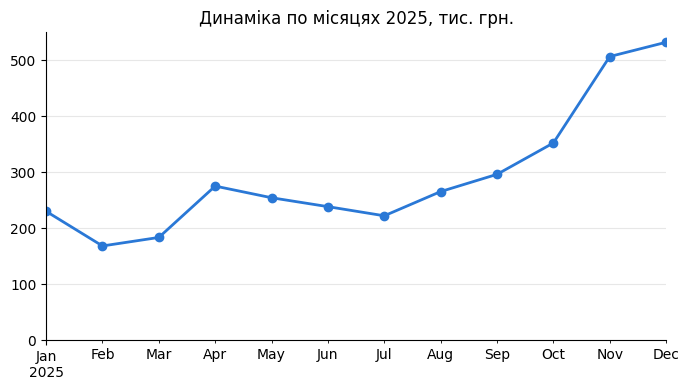


Найслабший місяць: 2025-02
Найкращий місяць: 2025-12


,revenue,profit,orders_count
month,,,
2025-01,230130,104640,178
2025-02,168220,80000,156
2025-03,183440,86260,156
2025-04,275200,126270,194
2025-05,254380,117610,197
2025-06,238470,109580,185
2025-07,222120,106160,190
2025-08,265400,120120,189
2025-09,296210,136730,221


In [21]:
# Ваш код тут
monthly = delivered.groupby("month").agg(
    revenue = ("revenue", "sum"),
    profit = ("profit", "sum"),
    orders_count = ("order_id", "count")
)

(monthly["revenue"] / 1000).plot(marker="o")
plt.title("Динаміка по місяцях 2025, тис. грн.")
plt.xlabel("")
plt.ylim(bottom=0)
plt.show()

print("\nНайслабший місяць:", monthly["revenue"].idxmin())
print("Найкращий місяць:", monthly["revenue"].idxmax())
monthly


---
## Крок 5. Товари та категорії

**Завдання:**
1. Знайдіть топ-5 товарів за **виручкою** і топ-5 за **прибутком**. Чи збігаються списки?
2. Створіть таблицю **`categories`**: виручка, прибуток і маржа (`margin_%` = прибуток / виручка × 100) по категоріях.
3. 📈 Побудуйте горизонтальний графік прибутку по категоріях: найбільша зверху, з підписами значень.

Топ-5 товарів за виручкою:
product
Smartwatch           483000
Perfume              326400
Bluetooth speaker    277200
Sneakers             252000
Hoodie               243600
Name: revenue, dtype: int64

Топ-5 товарів за прибутком:
product
Perfume              149600
Smartwatch           149500
Hoodie               131950
Sneakers             108000
Bluetooth speaker    105600
Name: profit, dtype: int64


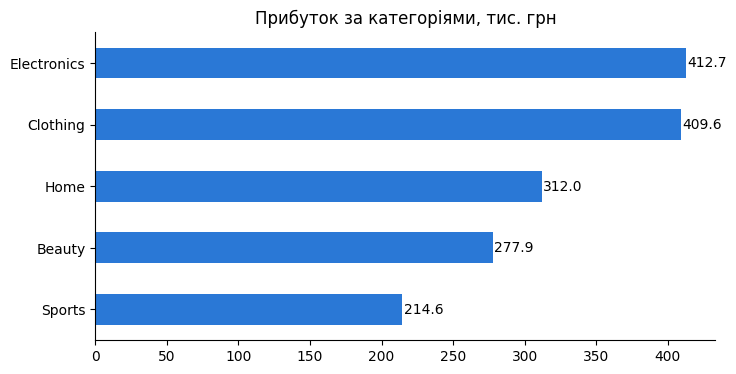

,revenue,profit,margin_%
category,,,
Electronics,1143600,412680,36.10
Clothing,812700,409570,50.40
Home,594480,312020,52.50
Beauty,544540,277870,51.00
Sports,429500,214560,50.00


In [34]:
# Ваш код тут
product_stats = delivered.groupby("product").agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
)
print("Топ-5 товарів за виручкою:")
print(product_stats["revenue"].nlargest(5))
print("\nТоп-5 товарів за прибутком:")
print(product_stats["profit"].nlargest(5))

categories = delivered.groupby("category").agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
)
categories["margin_%"] = (categories["profit"] / categories["revenue"] * 100).round(1)
categories = categories.sort_values("profit", ascending=False)

ax = (categories["profit"] / 1000).sort_values().plot(kind="barh", width=0.5)
ax.bar_label(ax.containers[0], fmt="%.1f", padding=1)
ax.grid(False)
plt.title("Прибуток за категоріями, тис. грн")
plt.ylabel("")
plt.show()

categories



---
## Крок 6. Міста і канали продажів

**Завдання:**
Побудуйте зведену таблицю **`city_channel`**: рядки — міста, стовпці — канали продажів, у клітинках — виручка (по доставлених), з рядком і стовпцем «Всього». Яке місто і який канал дають найбільше?

In [41]:
# Ваш код тут
city_channel = pd.pivot_table(
    delivered,
    index="city",
    columns="channel",
    values="revenue",
    aggfunc="sum",
    margins=True,
    margins_name="Всього"
)
#city_channel
city_channel.style.format("{:,.0f}")


channel,App,Instagram,Website,Всього
city,,,,
Dnipro,"172,750","79,490","228,510","480,750"
Kharkiv,"202,170","106,270","255,520","563,960"
Kyiv,"364,070","169,220","599,060","1,132,350"
Lviv,"252,670","157,160","377,660","787,490"
Odesa,"214,740","65,830","279,700","560,270"
Всього,"1,206,400","577,970","1,740,450","3,524,820"


---
## Крок 7. Клієнти

**Завдання:**
1. Порахуйте для кожного покупця кількість доставлених замовлень і їхню загальну суму. Назвіть таблицю **`buyers`**.
2. Яка частка покупців купила **більше одного разу** (повторні покупці)?
3. Складіть **`top10`** — 10 клієнтів з найбільшою сумою покупок, з іменем і містом.
4. ⭐ Розбийте покупців на вікові групи (18–24, 25–34, 35–44, 45+) і порахуйте виручку кожної групи.

In [54]:
# Ваш код тут
buyers = delivered.groupby("customer_id").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
)

print("Частка повторних покупців, %: ", round((buyers["orders"] > 1).mean() * 100, 1))

top10 = buyers.merge(customers[["customer_id", "name", "city"]], on="customer_id", how="left")
top10 = top10.nlargest(10, "revenue")
print("\nТоп-10 покупців:")
top10



Частка повторних покупців, %:  85.3

Топ-10 покупців:


,customer_id,orders,revenue,name,city
218,C0252,37,56090,Olena,Lviv
164,C0191,37,50830,Oleksandr,Kyiv
309,C0350,27,45440,Ihor,Kyiv
82,C0093,28,41800,Ihor,Kyiv
41,C0045,22,40830,Mariia,Kharkiv
193,C0224,22,39250,Taras,Kyiv
239,C0275,29,38780,Ihor,Kharkiv
138,C0161,23,37940,Dmytro,Lviv
152,C0178,27,35000,Serhii,Lviv
304,C0345,20,34970,Oksana,Dnipro


In [60]:
delivered["age_group"] = pd.cut(
    delivered["age"],
    bins=[17, 24, 34, 44, 100],
    labels=["18–24", "25–34", "35–44", "45+"],
)
age_revenue = delivered.groupby("age_group", observed=True)["revenue"].sum()
print("Сума дохода для кожної вікової групи:")
age_revenue

Сума дохода для кожної вікової групи:


,revenue
age_group,
18–24,648980
25–34,1559120
35–44,1023470
45+,293250


---
## Крок 8. Де проблеми?

**Завдання:**
1. Яка частка скасованих і повернених замовлень для кожного **способу оплати** (по **всіх** замовленнях `data`)?
2. Як середня оцінка залежить від **часу доставки** (`delivery_days`)?
3. Який середній час доставки в кожному місті?

Які проблеми ви бачите і що можна порадити бізнесу?

In [99]:
# Ваш код тут
print("Частка скасованих і повернених замовлень для кожного спосубу оплати, %:")
display((pd.crosstab(data["payment"], data["status"], normalize="index") * 100).round(1))

print("\nСередня оцінка залежить від часу доставки:")
display(delivered.groupby("delivery_days")["rating"].mean())

print("\nСередній час доставки в кожному місті:")
display(delivered.groupby("city")["delivery_days"].mean())


Частка скасованих і повернених замовлень для кожного спосубу оплати, %:


status,Cancelled,Delivered,Returned
payment,,,
Card,5.60,91.20,3.20
Cash on delivery,11.40,81.10,7.50
Google/Apple Pay,4.10,92.60,3.30



Середня оцінка залежить від часу доставки:


,rating
delivery_days,
1.00,4.21
2.00,4.17
3.00,4.11
4.00,3.53
5.00,3.53



Середній час доставки в кожному місті:


,delivery_days
city,
Dnipro,3.05
Kharkiv,2.83
Kyiv,1.50
Lviv,3.03
Odesa,2.98


---
## 📈 Крок 9. Дашборд на одній картинці

Керівник не читатиме десять таблиць. Зберіть **чотири головні графіки** на одній картинці (сітка 2 × 2), щоб усю історію року було видно за 10 секунд:

| Місце | Що показує | Питання |
|---|---|---|
| ліворуч угорі | виручка по місяцях | як ішли продажі? |
| праворуч угорі | прибуток по категоріях | що заробляє гроші? |
| ліворуч унизу | частка скасованих замовлень за способом оплати | де втрачаємо? |
| праворуч унизу | середня оцінка залежно від днів доставки | що дратує клієнтів? |

**Завдання:**
1. Побудуйте дашборд зі спільним заголовком.
2. Виділіть кольором те, на що керівник має звернути увагу (найгірший спосіб оплати, довгу доставку), а решту залиште нейтральною.
3. Збережіть дашборд у файл **`dashboard_2025.png`**.

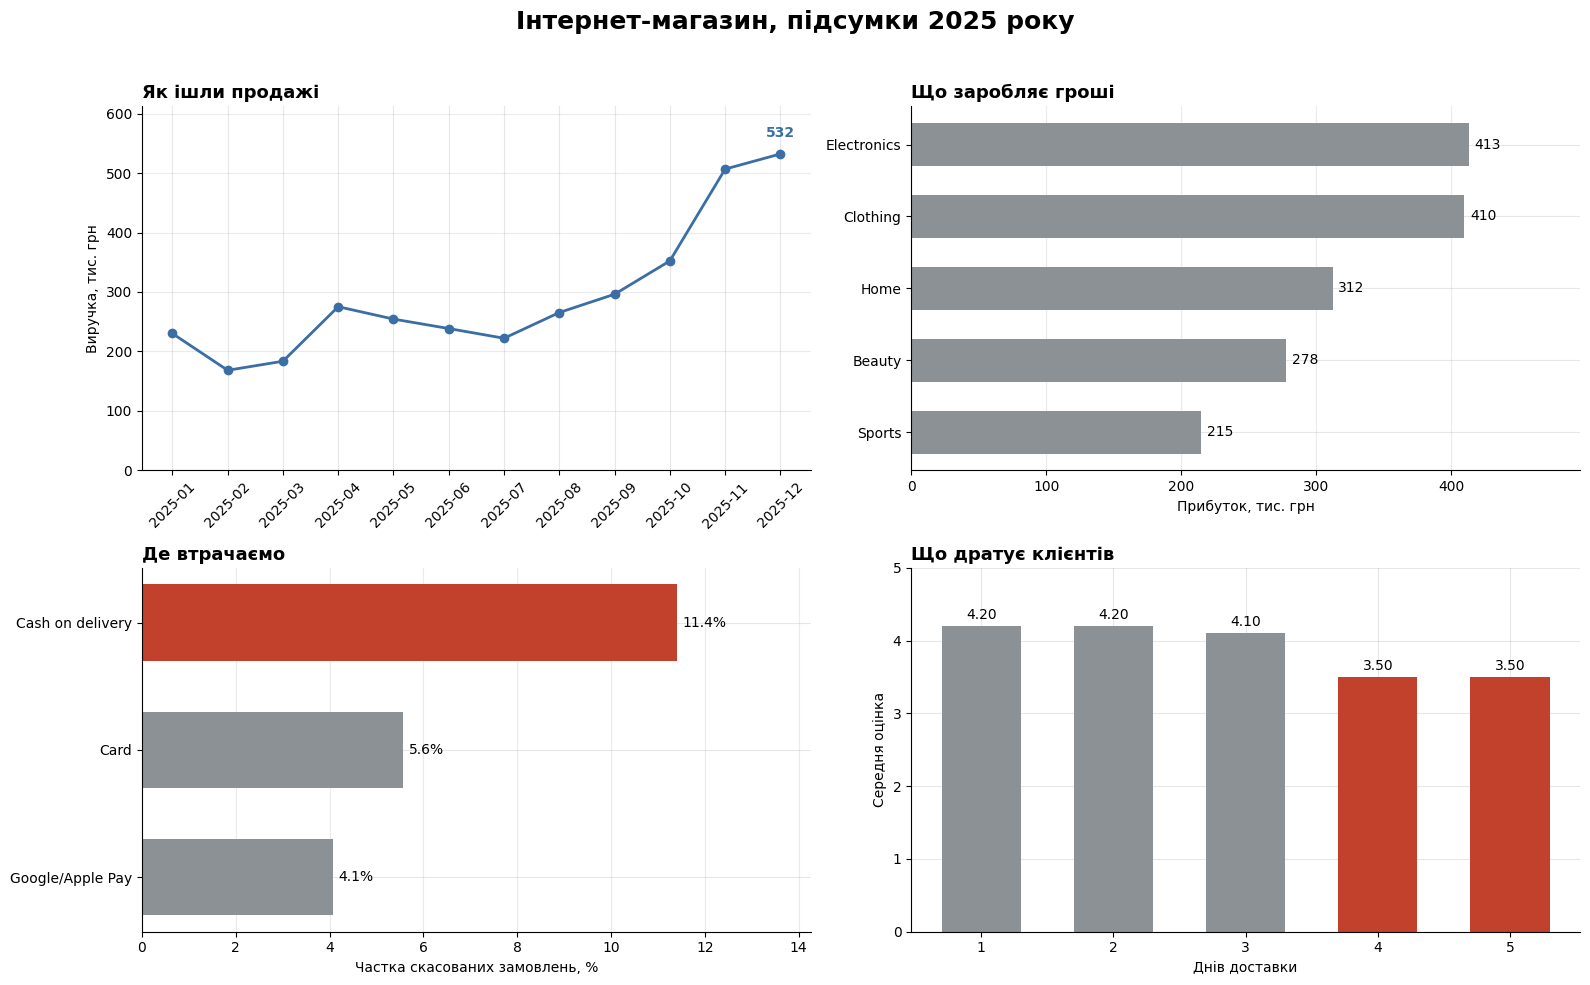

In [90]:
# Ваш код тут
import matplotlib.pyplot as plt

NEUTRAL = "#8C9196"   # сірий — фон історії
ACCENT  = "#C2412D"   # червоний — те, на що треба дивитися
LINE    = "#3A6EA5"   # синій — динаміка

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Інтернет-магазин, підсумки 2025 року",
             fontsize=18, fontweight="bold", y=0.98)

def clean(ax):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.set_axisbelow(True)

# Ліворуч угорі: виручка по місяцях
ax = axes[0, 0]
x = monthly.index.astype(str)
y = monthly["revenue"] / 1000
ax.plot(x, y, marker="o", markersize=6, linewidth=2, color=LINE)
ax.set_ylim(0, y.max() * 1.15)
ax.set_title("Як ішли продажі", fontsize=13, fontweight="bold", loc="left")
ax.set_ylabel("Виручка, тис. грн")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.annotate(f"{y.iloc[-1]:.0f}", (len(x) - 1, y.iloc[-1]),
            textcoords="offset points", xytext=(0, 12),
            ha="center", fontsize=10, color=LINE, fontweight="bold")
clean(ax)

# Праворуч угорі: прибуток по категоріях
ax = axes[0, 1]
cat = (categories["profit"] / 1000).sort_values()
bars = ax.barh(cat.index, cat.values, color=NEUTRAL, height=0.6)
ax.bar_label(bars, fmt="%.0f", padding=4, fontsize=10)
ax.set_xlim(0, cat.max() * 1.2)
ax.set_title("Що заробляє гроші", fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Прибуток, тис. грн")
ax.grid(axis="x", alpha=0.25)
clean(ax)

# Ліворуч унизу: скасування за способом оплати
ax = axes[1, 0]
cancel = (data.groupby("payment")["status"]
              .apply(lambda s: (s == "Cancelled").mean() * 100)
              .sort_values())
colors = [ACCENT if v == cancel.max() else NEUTRAL for v in cancel.values]
bars = ax.barh(cancel.index, cancel.values, color=colors, height=0.6)
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=10)
ax.set_xlim(0, cancel.max() * 1.25)
ax.set_title("Де втрачаємо", fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Частка скасованих замовлень, %")
ax.grid(axis="x", alpha=0.25)
clean(ax)

# Праворуч унизу: оцінка залежно від днів доставки
ax = axes[1, 1]
LONG = 4                                   # з якого дня доставка вважається довгою
r = delivered.groupby("delivery_days")["rating"].mean().round(1)
colors = [ACCENT if d >= LONG else NEUTRAL for d in r.index]
bars = ax.bar(r.index.astype(int).astype(str), r.values, color=colors, width=0.6)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=10)
ax.set_ylim(0, 5)
ax.set_title("Що дратує клієнтів", fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Днів доставки")
ax.set_ylabel("Середня оцінка")
ax.grid(axis="y", alpha=0.3)
clean(ax)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("dashboard_2025.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()


In [91]:
from google.colab import files
files.download("dashboard_2025.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Крок 10. Звіт в Excel

**Завдання:**
1. Збережіть таблиці в **один файл** `report_2025.xlsx` з аркушами: KPI, Місяці, Категорії, Міста і канали, Топ-10 клієнтів.
2. 📈 Додайте аркуш «Дашборд» і вставте на нього картинку з кроку 9.
3. Перевірте результат: прочитайте файл назад і переконайтеся, що всі аркуші на місці.

In [96]:
# Ваш код тут
import pandas as pd
from openpyxl.drawing.image import Image as XLImage

FILE = "report_2025.xlsx"

# Period → текст, інакше Excel не запише
monthly_x = monthly.copy()
monthly_x.index = monthly_x.index.astype(str)

with pd.ExcelWriter(FILE, engine="openpyxl") as writer:
    kpi.to_frame("Значення").to_excel(writer, sheet_name="KPI")
    monthly_x.to_excel(writer, sheet_name="Місяці")
    categories.to_excel(writer, sheet_name="Категорії")
    city_channel.to_excel(writer, sheet_name="Міста і канали")
    top10.to_excel(writer, sheet_name="Топ-10 клієнтів", index=False)

    # окремий аркуш із картинкою
    ws = writer.book.create_sheet("Дашборд")
    img = XLImage("dashboard_2025.png")
    img.width  = int(img.width  * 0.45)     # 2400px завузько не влізе
    img.height = int(img.height * 0.45)
    ws.add_image(img, "B2")

print("Готово:", FILE)

Готово: report_2025.xlsx


In [95]:
from google.colab import files
files.download(FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Крок 11. Висновки для керівника

Цифри самі по собі нічого не означають, поки аналітик не перетворить їх на **висновки й рекомендації**. Це найважливіша частина роботи.

**Завдання:** напишіть 4–5 коротких висновків. Кожен висновок — це **факт з цифрою** і **рекомендація**.

**Мої висновки** (двічі клацніть, щоб редагувати):

1. Рік розділився навпіл. Друге півріччя — 2.17 млн грн проти 1.35 млн у першому (+61%), а один лише Q4 дав 39% річної виручки. Найслабший місяць — лютий (168 тис.), найсильніший — грудень (532 тис.), різниця більш ніж утричі.
Рекомендація: з'ясувати природу піку — якщо це сезонність, її треба просто обслужити; якщо наслідок конкретних акцій, ті самі механіки варто повторити у провальному Q1.
2. Листопад і грудень заробляють по-різному. У листопаді 418 замовлень із середнім чеком 1212 грн, у грудні — 355 замовлень із чеком 1499 грн. При цьому маржа грудня нижча: 44.8% проти 47.7%.
Рекомендація: грудневу виручку роблять дорогі подарункові позиції, тому під грудень потрібен запас саме їх.
3. Найбільша категорія — найменш вигідна. Електроніка дає 1.14 млн виручки (32% обороту) при маржі 36.1%, тоді як решта категорій тримають близько 50%. Одяг із виручкою на 29% меншою приносить практично той самий прибуток: 409.6 тис. проти 412.7 тис.
Рекомендація: переглянути закупівельні ціни або націнку на електроніці, починаючи зі Smartwatch (483 тис. виручки, лише 149.5 тис. прибутку).
4. Кожне дев'яте замовлення не доходить до покупця: 6.8% скасовано, 4.4% повернено, разом 11.2% від трьох тисяч замовлень. Найгірший спосіб оплати дає 4.1% скасувань проти 17% у решти.
Рекомендація: підтвердження замовлення перед відправкою саме для цього способу оплати, або передоплата від певної суми.

---
---
# 💡 Підказки

Тут зібрано підказки до кожного кроку. Спершу спробуйте сам(а), а сюди заглядайте, лише коли застрягли. Розв'язки ще нижче.

### 💡 Крок 1

- Читання файлу: `pd.read_csv("orders.csv")`.
- Огляд: `.shape`, `.head()`, `.info()`, `.isna().sum()`.
- Унікальність ключа: `orders["order_id"].duplicated().sum()` має дорівнювати 0.
- Пропуски в `delivery_date` і `rating` — це **не помилка**: подумайте, які замовлення не доставляли і чи всі клієнти ставлять оцінки.
- 📚 Блокноти 1 і 3.

### 💡 Крок 2

- Текст → дата: `pd.to_datetime(orders["order_date"])`.
- Об'єднання ланцюжком: `orders.merge(products, on="product_id", how="left").merge(customers, on="customer_id", how="left")`.
- Перевірка: `len(orders) == len(data)`. Можна додати `validate="many_to_one"`.
- Місяць: `data["order_date"].dt.to_period("M")`.
- Дні доставки: `(data["delivery_date"] - data["order_date"]).dt.days`.
- Фільтр з копією: `data[data["status"] == "Delivered"].copy()`.
- 📚 Блокноти 3, 5 і 6.

### 💡 Крок 3

- Series з назвами: `pd.Series({"Виручка, грн": ..., "Прибуток, грн": ...})`.
- Кількість покупців: `.nunique()`.
- **Частка** = середнє від `True`/`False`: `(data["status"] == "Cancelled").mean() * 100`.
- Щоб цілі числа не перетворилися на дробові, додайте `dtype=object` у `pd.Series(...)`.

### 💡 Крок 4

- Кілька метрик одразу: `delivered.groupby("month").agg(revenue=("revenue", "sum"), profit=(...), orders=("order_id", "count"))`.
- Графік: `(monthly["revenue"] / 1000).plot(marker="o")`, потім `plt.ylim(bottom=0)`.
- Найкращий і найгірший місяць: `monthly["revenue"].idxmax()` і `.idxmin()`.
- 📚 Блокноти 4 і 6.

### 💡 Крок 5

- Статистика по товарах: `delivered.groupby("product").agg(revenue=..., profit=...)`, потім `["revenue"].nlargest(5)`.
- Маржа: `categories["profit"] / categories["revenue"] * 100`.
- Графік: `sort_values()` перед `.plot(kind="barh")`, щоб найбільше було зверху; підписи — `ax.bar_label(ax.containers[0], fmt="%.0f")`.
- 📚 Блокноти 2 і 4.

### 💡 Крок 6

- `pd.pivot_table(delivered, index="city", columns="channel", values="revenue", aggfunc="sum", margins=True, margins_name="Всього")`.
- 📚 Блокнот 4.

### 💡 Крок 7

- Покупці: `delivered.groupby("customer_id").agg(orders=("order_id", "count"), revenue=("revenue", "sum")).reset_index()`.
- Частка повторних: `(buyers["orders"] > 1).mean() * 100`.
- Ім'я та місто: `buyers.merge(customers[["customer_id", "name", "city"]], on="customer_id", how="left")`, потім `.nlargest(10, "revenue")`.
- Вікові групи: `pd.cut(delivered["age"], bins=[17, 24, 34, 44, 100], labels=["18–24", "25–34", "35–44", "45+"])`.
- Групування за результатом `pd.cut`: додайте `observed=True` у `groupby(...)`.
- 📚 Блокноти 3, 4 і 5.

### 💡 Крок 8

- Частки статусів: `pd.crosstab(data["payment"], data["status"], normalize="index") * 100`.
- Оцінка й доставка: `data.groupby("delivery_days")["rating"].mean()`.
- Доставка по містах: `data.groupby("city")["delivery_days"].mean()`.
- Порівняйте `Cash on delivery` з іншими способами оплати, а 1–3 дні доставки з 4–5 днями.

### 💡 Крок 9

- Сітка: `fig, axes = plt.subplots(2, 2, figsize=(14, 9))`. Полотно позначають двома числами: `axes[рядок, стовпець]`, наприклад `axes[1, 0]` — ліве нижнє.
- Малювати на полотні: `.plot(..., ax=axes[0, 0])`; заголовок: `axes[0, 0].set_title("...")`.
- Частка скасованих за оплатою: `pd.crosstab(data["payment"], data["status"], normalize="index")["Cancelled"] * 100`.
- Виділення кольором: `colors = ["#e34948" if x == s.idxmax() else "#c3c2b7" for x in s.index]`.
- Підписи на стовпчиках: `axes[1, 0].bar_label(axes[1, 0].containers[0], fmt="%.1f%%")`.
- Наприкінці: `fig.suptitle("...")`, `plt.tight_layout()`, а `plt.savefig("dashboard_2025.png", dpi=150, bbox_inches="tight")` — **перед** `plt.show()`.
- 📚 Блокноти 2, 3 і 6.

### 💡 Крок 10

Кілька аркушів в одному файлі:
```python
with pd.ExcelWriter("report_2025.xlsx", engine="openpyxl") as writer:
    table1.to_excel(writer, sheet_name="Назва аркуша 1")
    table2.to_excel(writer, sheet_name="Назва аркуша 2")
```
- `kpi` — це Series, тому спочатку `kpi.to_frame("Значення")`.
- Місяці в `monthly` мають тип «період», якого Excel не розуміє: перетворіть індекс на текст, `monthly.index.astype(str)`.
- Картинка на окремий аркуш (усередині того самого блоку `with`):
```python
from openpyxl.drawing.image import Image as ExcelImage

sheet = writer.book.create_sheet("Дашборд")
sheet.add_image(ExcelImage("dashboard_2025.png"), "A1")
```
- Перевірка: `pd.read_excel("report_2025.xlsx", sheet_name=None)` повертає всі аркуші. Аркуш з картинкою pandas покаже порожнім — це нормально.

### 💡 Крок 11

Формула хорошого висновку: **факт з цифрою → що це означає → що робити**.

> ❌ «Cash on delivery — погано».
> ✅ «Замовлення з оплатою `Cash on delivery` скасовують удвічі частіше, ніж оплачені карткою. Варто протестувати знижку 3% за онлайн-оплату.»

Про що можна написати: найкращий і найгірший місяць, різниця між виручкою і прибутком категорій, скасування за способом оплати, час доставки й оцінки, частка повторних покупців.

---
---
# ✅ Розв'язки

Кожен розв'язок схований. Щоб подивитися код, натисніть «Показати код». Якщо запустити розв'язок, він створить змінні цього кроку, і можна продовжувати з наступного.

⚠️ Розв'язки спираються один на одного, тому запускайте їх **по черзі**, починаючи з кроку 1.

### ✅ Крок 1. Завантаження і перевірка даних

In [4]:
# @title ✅ Розв'язок кроку 1
orders = pd.read_csv("orders.csv")
customers = pd.read_csv("customers.csv")
products = pd.read_csv("products.csv")

for name, table in [("orders", orders), ("customers", customers), ("products", products)]:
    print(f"{name}: {table.shape[0]} рядків, {table.shape[1]} стовпців")

print("\nПропуски в orders:")
print(orders.isna().sum()[orders.isna().sum() > 0])

print("\nДублікати ключів:")
print("  order_id:   ", orders["order_id"].duplicated().sum())
print("  customer_id:", customers["customer_id"].duplicated().sum())
print("  product_id: ", products["product_id"].duplicated().sum())
# Пропуски лише в delivery_date (скасовані замовлення не доставляли)
# і rating (не всі клієнти ставлять оцінки). Це нормально.

orders: 3000 рядків, 10 стовпців
customers: 400 рядків, 5 стовпців
products: 18 рядків, 5 стовпців

Пропуски в orders:
delivery_date     205
rating           1255
dtype: int64

Дублікати ключів:
  order_id:    0
  customer_id: 0
  product_id:  0


### ✅ Крок 2. Підготовка: одна велика таблиця

In [ ]:
# @title ✅ Розв'язок кроку 2
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders["delivery_date"] = pd.to_datetime(orders["delivery_date"])

data = (
    orders
    .merge(products, on="product_id", how="left", validate="many_to_one")
    .merge(customers, on="customer_id", how="left", validate="many_to_one")
)
print("Замовлень:", len(orders), "| рядків після об'єднання:", len(data))

data["revenue"] = data["price"] * data["quantity"]
data["profit"] = (data["price"] - data["cost"]) * data["quantity"]
data["month"] = data["order_date"].dt.to_period("M")
data["delivery_days"] = (data["delivery_date"] - data["order_date"]).dt.days

delivered = data[data["status"] == "Delivered"].copy()
print("Доставлених замовлень:", len(delivered))
data.head(3)

### ✅ Крок 3. Ключові показники (KPI)

In [ ]:
# @title ✅ Розв'язок кроку 3
kpi = pd.Series({
    "Виручка, грн": delivered["revenue"].sum(),
    "Прибуток, грн": delivered["profit"].sum(),
    "Доставлених замовлень": len(delivered),
    "Середній чек, грн": round(delivered["revenue"].mean(), 2),
    "Покупців": delivered["customer_id"].nunique(),
    "Скасовано, %": round((data["status"] == "Cancelled").mean() * 100, 1),
    "Повернено, %": round((data["status"] == "Returned").mean() * 100, 1),
    "Середня оцінка": round(data["rating"].mean(), 2),
}, dtype=object)
kpi

### ✅ Крок 4. Динаміка по місяцях

In [ ]:
# @title ✅ Розв'язок кроку 4
monthly = delivered.groupby("month").agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "count"),
)

(monthly["revenue"] / 1000).plot(marker="o")
plt.title("Виручка по місяцях 2025, тис. грн")
plt.xlabel("")
plt.ylim(bottom=0)
plt.show()

print("Найкращий місяць:", monthly["revenue"].idxmax())
print("Найслабший місяць:", monthly["revenue"].idxmin())
monthly

### ✅ Крок 5. Товари та категорії

In [ ]:
# @title ✅ Розв'язок кроку 5
product_stats = delivered.groupby("product").agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
)
print("Топ-5 за виручкою:")
print(product_stats["revenue"].nlargest(5))
print("\nТоп-5 за прибутком:")
print(product_stats["profit"].nlargest(5))

categories = delivered.groupby("category").agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
)
categories["margin_%"] = (categories["profit"] / categories["revenue"] * 100).round(1)
categories = categories.sort_values("profit", ascending=False)

ax = (categories["profit"] / 1000).sort_values().plot(kind="barh", width=0.7)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
plt.title("Прибуток по категоріях, тис. грн")
plt.ylabel("")
plt.show()

categories

### ✅ Крок 6. Міста і канали продажів

In [ ]:
# @title ✅ Розв'язок кроку 6
city_channel = pd.pivot_table(
    delivered,
    index="city",
    columns="channel",
    values="revenue",
    aggfunc="sum",
    margins=True,
    margins_name="Всього",
)
city_channel

### ✅ Крок 7. Клієнти

In [ ]:
# @title ✅ Розв'язок кроку 7
buyers = delivered.groupby("customer_id").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
).reset_index()

repeat_share = (buyers["orders"] > 1).mean() * 100
print(f"Повторних покупців: {repeat_share:.1f}%")

top10 = (
    buyers.merge(customers[["customer_id", "name", "city"]], on="customer_id", how="left")
    .nlargest(10, "revenue")
    .reset_index(drop=True)
)
display(top10)

delivered["age_group"] = pd.cut(
    delivered["age"],
    bins=[17, 24, 34, 44, 100],
    labels=["18–24", "25–34", "35–44", "45+"],
)
age_revenue = delivered.groupby("age_group", observed=True)["revenue"].sum()
age_revenue

### ✅ Крок 8. Де проблеми?

In [ ]:
# @title ✅ Розв'язок кроку 8
print("Статуси за способом оплати, %:")
display((pd.crosstab(data["payment"], data["status"], normalize="index") * 100).round(1))

print("Середня оцінка за часом доставки:")
display(data.groupby("delivery_days")["rating"].mean().round(2).to_frame())

print("Середній час доставки по містах, дн.:")
data.groupby("city")["delivery_days"].mean().round(1).sort_values().to_frame()

### ✅ Крок 9. Дашборд

In [ ]:
# @title ✅ Розв'язок кроку 9
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Виручка по місяцях
(monthly["revenue"] / 1000).plot(ax=axes[0, 0], marker="o")
axes[0, 0].set_title("Виручка по місяцях, тис. грн")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylim(bottom=0)

# 2. Прибуток по категоріях
profit_k = (categories["profit"] / 1000).sort_values()
profit_k.plot(kind="barh", ax=axes[0, 1], width=0.7)
axes[0, 1].bar_label(axes[0, 1].containers[0], fmt="%.0f", padding=3)
axes[0, 1].set_title("Прибуток по категоріях, тис. грн")
axes[0, 1].set_ylabel("")
axes[0, 1].set_xticks([])
axes[0, 1].grid(False)
axes[0, 1].spines["bottom"].set_visible(False)

# 3. Частка скасованих замовлень за способом оплати (найгірший — червоний)
cancel_rate = (pd.crosstab(data["payment"], data["status"], normalize="index")["Cancelled"] * 100).sort_values()
colors = ["#e34948" if p == cancel_rate.idxmax() else "#c3c2b7" for p in cancel_rate.index]
cancel_rate.plot(kind="barh", ax=axes[1, 0], color=colors, width=0.6)
axes[1, 0].bar_label(axes[1, 0].containers[0], fmt="%.1f%%", padding=3)
axes[1, 0].set_title("Частка скасованих замовлень, %")
axes[1, 0].set_ylabel("")
axes[1, 0].set_xticks([])
axes[1, 0].grid(False)
axes[1, 0].spines["bottom"].set_visible(False)

# 4. Середня оцінка залежно від днів доставки (4+ днів — червоні)
rating_by_days = data.groupby("delivery_days")["rating"].mean()
rating_by_days.index = rating_by_days.index.astype(int)
colors = ["#e34948" if days >= 4 else "#2a78d6" for days in rating_by_days.index]
rating_by_days.plot(kind="bar", ax=axes[1, 1], color=colors, rot=0, width=0.6)
axes[1, 1].bar_label(axes[1, 1].containers[0], fmt="%.2f", padding=3)
axes[1, 1].set_title("Середня оцінка залежно від днів доставки")
axes[1, 1].set_xlabel("Днів доставки")
axes[1, 1].set_ylim(0, 5)
axes[1, 1].set_yticks([])
axes[1, 1].grid(False)
axes[1, 1].spines["left"].set_visible(False)

fig.suptitle("Інтернет-магазин: підсумки 2025 року", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("dashboard_2025.png", dpi=150, bbox_inches="tight")
plt.show()

### ✅ Крок 10. Звіт в Excel

In [ ]:
# @title ✅ Розв'язок кроку 10
from openpyxl.drawing.image import Image as ExcelImage

monthly_xl = monthly.copy()
monthly_xl.index = monthly_xl.index.astype(str)       # 2025-01, 2025-02, ...

with pd.ExcelWriter("report_2025.xlsx", engine="openpyxl") as writer:
    kpi.to_frame("Значення").to_excel(writer, sheet_name="KPI")
    monthly_xl.to_excel(writer, sheet_name="Місяці")
    categories.to_excel(writer, sheet_name="Категорії")
    city_channel.to_excel(writer, sheet_name="Міста і канали")
    top10.to_excel(writer, sheet_name="Топ-10 клієнтів", index=False)

    dashboard_sheet = writer.book.create_sheet("Дашборд")
    picture = ExcelImage("dashboard_2025.png")
    picture.width, picture.height = picture.width // 2, picture.height // 2   # зменшити вдвічі
    dashboard_sheet.add_image(picture, "A1")

print("✅ Звіт збережено: report_2025.xlsx")
print("Щоб завантажити: панель 📁 ліворуч → ⋮ біля файлу → «Завантажити»\n")

# Перевірка: читаємо всі аркуші назад
report = pd.read_excel("report_2025.xlsx", sheet_name=None)
for sheet_name, sheet in report.items():
    print(f"{sheet_name}: {sheet.shape[0]} рядків")

### ✅ Крок 11. Приклад висновків

<details>
<summary><b>Розгорнути приклад</b> (після того, як напишете свої)</summary>

1. **Результат року.** Виручка 3,52 млн грн, прибуток 1,63 млн грн (маржа ≈ 46%), 2 664 доставлені замовлення, середній чек ≈ 1 323 грн.
2. **Сильна сезонність.** Листопад і грудень разом дали майже 30% річної виручки, а найслабший місяць — лютий (168 тис. грн, утричі менше за грудень). *Рекомендація:* заздалегідь готувати запаси й рекламу до Чорної п'ятниці та свят, а на лютий планувати акції.
3. **Виручка ≠ прибуток.** `Electronics` лідирує за виручкою (1,14 млн грн), але її маржа лише 36%. `Clothing` при виручці 0,81 млн грн приносить майже такий самий прибуток (410 тис. грн) з маржею 50%. *Рекомендація:* розвивати `Clothing` і переглянути закупівельні ціни на електроніку.
4. **Накладений платіж — головне джерело втрат.** Замовлення з `Cash on delivery` скасовують удвічі частіше, ніж оплачені карткою (11,4% проти 5,6%), а повертають більш ніж удвічі частіше (7,5% проти 3,2%). *Рекомендація:* протестувати знижку або бонус за онлайн-оплату.
5. **Довга доставка псує оцінки.** Якщо доставка триває 1–3 дні, середня оцінка понад 4,0, а якщо 4–5 днів — лише ≈ 3,45. У Kyiv доставка в середньому займає 1,5 дня, в інших містах — близько 3 днів. *Рекомендація:* шукати швидшу логістику для регіонів.
6. **Лояльна база.** 85% покупців купували більше одного разу, а Kyiv дає близько третини виручки.

</details>

---
# 🎁 Бонус: інтерактивний графік (plotly)

У Colab є бібліотека **plotly**: її графіки інтерактивні. Наведіть курсор на точку, і побачите точне значення; ділянку графіка можна наблизити мишкою.

⚠️ Клітинки нижче використовують `monthly` і `categories` з кроків 4–5.

In [ ]:
import plotly.express as px

monthly_plot = monthly.reset_index()
monthly_plot["month"] = monthly_plot["month"].astype(str)

fig = px.line(
    monthly_plot, x="month", y="revenue", markers=True,
    title="Виручка по місяцях 2025 (наведіть курсор на точку)",
    labels={"month": "Місяць", "revenue": "Виручка, грн"},
)
fig.show()

In [ ]:
category_plot = categories.reset_index().sort_values("profit")

fig = px.bar(
    category_plot, x="profit", y="category", orientation="h",
    hover_data=["revenue", "margin_%"],              # що ще показати у підказці
    title="Прибуток по категоріях (наведіть курсор на стовпчик)",
    labels={"profit": "Прибуток, грн", "category": "", "revenue": "Виручка, грн", "margin_%": "Маржа, %"},
)
fig.show()

---
# 📈 Шпаргалка: який графік обрати

| Питання | Графік | Як у pandas |
|---|---|---|
| Як змінювалося з часом? | лінійний | `s.plot()` |
| Хто більше, хто менше? | горизонтальні стовпчики, відсортовані | `s.sort_values().plot(kind="barh")` |
| Порівняти кілька показників у групах | згруповані стовпчики | `pivot.plot(kind="bar")` |
| З чого складається ціле? | складені або 100%-ві стовпчики | `pivot.plot(kind="barh", stacked=True)` |
| Як розподілені значення? | гістограма | `s.plot(kind="hist", bins=20)` |
| Чи є зв'язок між двома числами? | точкова діаграма | `df.plot(kind="scatter", x=..., y=...)` |
| Багато категорій у динаміці | малі мультиплікатори | `pivot.plot(subplots=True, layout=(2, 3), sharey=True)` |
| Потрібні точні числа | теплова таблиця | `table.style.background_gradient()` |

### ⚠️ Типові помилки
1. **Немає заголовка або одиниць виміру.** Читач не знає, що це: гривні, штуки чи відсотки.
2. **Стовпчики не від нуля.** Невелика різниця виглядає як прірва. Для стовпчиків вісь завжди починається з 0.
3. **Невідсортовані категорії.** Читачеві доводиться самому шукати найбільше.
4. **Кругова діаграма з багатьма секторами.** Кути око порівнює погано, а 5+ секторів не порівнює взагалі. Краще горизонтальні стовпчики.
5. **Дві осі Y на одному графіку.** Майже завжди заплутують. Краще два графіки поруч (`plt.subplots`).
6. **Забагато кольорів.** Колір має значення: виділяйте ним головне, решту робіть сірою.
7. **Заголовок без висновку.** «Продажі по місяцях» гірше, ніж «Продажі зросли вдвічі за осінь».